# 01 · Sydney Market Overview (2014–2023)

**Client:** Residential property investment fund, acquisitions team
**Questions answered here:**
- **Q1:** How have Sydney prices moved over the last decade, and what drove the cycles?
- **Q3:** Houses vs units: which kept pace with inflation?
- **Q5:** Is there a best time of year to buy?

**Data:** 881,664 Sydney-metro residential sales (NSW Valuer General), cleaned in `src/clean_sales.py`.
See `docs/data_quality_report.md` for every cleaning rule. Inflation uses the ABS Sydney CPI (table 6401017).

> **How to read medians:** a median price tracks *what sold*, not just *what it's worth*. If more expensive
> homes sell in one quarter, the median rises even if no home gained value. This notebook flags where that matters.
> Like-for-like growth (the repeat-sales index) is in Notebook 02.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from viz_style import (DWELLING_COLORS, DWELLING_ORDER, SEGMENT_COLORS, SEGMENT_ORDER, INK_2, MUTED, NEG, POS,
                       apply_style, money_axis, pct_axis, subtitle)

apply_style()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:,.1f}".format

sales = pd.read_parquet(ROOT / "data/processed/sydney_sales_clean.parquet")
cpi = pd.read_csv(ROOT / "data/external/cpi_sydney_quarterly.csv").set_index("quarter")["cpi_sydney"]

# Express every price in Dec-2023 dollars so "real" figures are comparable across years
BASE_Q = "2023Q4"
sales["real_price"] = sales["purchase_price"] * cpi[BASE_Q] / sales["quarter"].map(cpi)
# Trend segment: House vs all strata (see the Q3 data note for why townhouses are not tracked separately over time)
sales["segment"] = np.where(sales.dwelling_type == "House", "House", "Unit/Townhouse")
print(f"{len(sales):,} sales | {sales.contract_date.min():%b %Y} to {sales.contract_date.max():%b %Y}")
sales.groupby("dwelling_type").purchase_price.agg(sales="size", median_price="median")

881,664 sales | Jan 2014 to Dec 2023


,sales,median_price
dwelling_type,,
House,438380,"1,121,000.0"
Townhouse/Villa,39671,"755,000.0"
Unit,403613,"725,000.0"


## Q1 · How have Sydney prices moved, and what drove the cycles?

Quarterly median sale price across all dwellings, shown in **nominal** dollars and in **real** (Dec-2023) dollars.

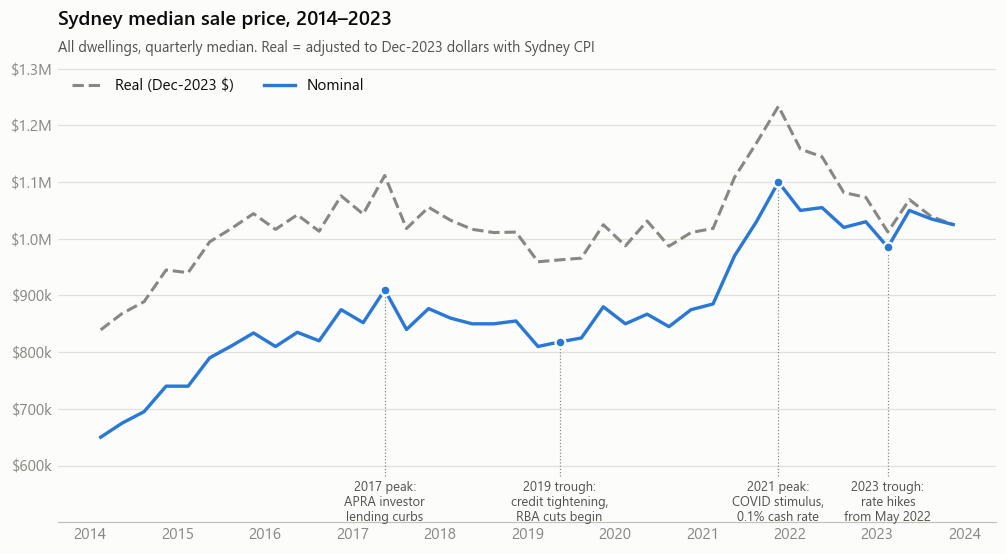

In [2]:
q = sales.groupby("quarter").agg(median_nominal=("purchase_price", "median"),
                                 median_real=("real_price", "median"),
                                 sales=("purchase_price", "size"))
q.index = pd.PeriodIndex(q.index, freq="Q")
x = q.index.start_time + pd.Timedelta(days=45)  # plot at mid-quarter

EVENTS = [  # (quarter, label): market context for the annotations
    ("2017Q2", "2017 peak:\nAPRA investor\nlending curbs"),
    ("2019Q2", "2019 trough:\ncredit tightening,\nRBA cuts begin"),
    ("2021Q4", "2021 peak:\nCOVID stimulus,\n0.1% cash rate"),
    ("2023Q1", "2023 trough:\nrate hikes\nfrom May 2022"),
]

fig, ax = plt.subplots(figsize=(11, 5.4))
ax.plot(x, q.median_real, color=MUTED, lw=2, ls="--", label="Real (Dec-2023 $)")
ax.plot(x, q.median_nominal, color=SEGMENT_COLORS["House"], lw=2.2, label="Nominal")
floor = min(q.median_nominal.min(), q.median_real.min()) * 0.82
for qtr, label in EVENTS:
    xi = pd.Period(qtr, "Q").start_time + pd.Timedelta(days=45)
    yi = q.loc[qtr, "median_nominal"]
    ax.vlines(xi, floor * 1.09, yi, color=MUTED, lw=0.8, ls=":")
    ax.scatter([xi], [yi], s=42, color=SEGMENT_COLORS["House"], zorder=3, edgecolor="white", linewidth=1.5)
    ax.text(xi, floor * 1.075, label, ha="center", va="top", fontsize=8.5, color=INK_2)
money_axis(ax)
ax.set_ylim(floor * 0.94, q.median_real.max() * 1.06)
ax.set_title("Sydney median sale price, 2014–2023")
subtitle(ax, "All dwellings, quarterly median. Real = adjusted to Dec-2023 dollars with Sydney CPI")
ax.legend(loc="upper left", ncol=2)
fig.savefig(FIG / "q1_price_cycle.png")
plt.show()

In [3]:
y = sales.groupby("year").agg(median_nominal=("purchase_price", "median"),
                              median_real=("real_price", "median"),
                              sales=("purchase_price", "size"))
y["yoy_nominal_%"] = y.median_nominal.pct_change() * 100
y["yoy_real_%"] = y.median_real.pct_change() * 100
first, last = y.index.min(), y.index.max()
total_nom = (y.median_nominal[last] / y.median_nominal[first] - 1) * 100
total_real = (y.median_real[last] / y.median_real[first] - 1) * 100
cpi_growth = (cpi[BASE_Q] / cpi["2014Q1"] - 1) * 100
print(f"{first}->{last}: nominal {total_nom:+.1f}% | real {total_real:+.1f}% | Sydney CPI {cpi_growth:+.1f}%")
peak17, trough19 = q.loc["2017Q1":"2018Q2", "median_nominal"], q.loc["2018Q3":"2019Q4", "median_nominal"]
peak21, trough23 = q.loc["2021Q1":"2022Q2", "median_nominal"], q.loc["2022Q3":"2023Q4", "median_nominal"]
print(f"2017 peak->2019 trough: {(trough19.min()/peak17.max()-1)*100:+.1f}%   "
      f"2019 trough->2021 peak: {(peak21.max()/trough19.min()-1)*100:+.1f}%   "
      f"2021 peak->2023 trough: {(trough23.min()/peak21.max()-1)*100:+.1f}%")
y

2014->2023: nominal +48.6% | real +16.9% | Sydney CPI +29.1%
2017 peak->2019 trough: -11.0%   2019 trough->2021 peak: +35.8%   2021 peak->2023 trough: -10.5%


,median_nominal,median_real,sales,yoy_nominal_%,yoy_real_%
year,,,,,
2014,"690,000.0","887,441.4",107387,NaN,NaN
2015,"794,000.0","998,176.0",106899,15.1,12.5
2016,"839,000.0","1,039,331.5",88848,5.7,4.1
2017,"870,000.0","1,059,400.1",88475,3.7,1.9
2018,"853,000.0","1,017,731.1",67251,-2.0,-3.9
2019,"835,000.0","978,175.6",72410,-2.1,-3.9
2020,"860,000.0","1,002,494.0",81356,3.0,2.5
2021,"985,000.0","1,121,610.4",109083,14.5,11.9
2022,"1,040,000.0","1,113,355.0",78456,5.6,-0.7


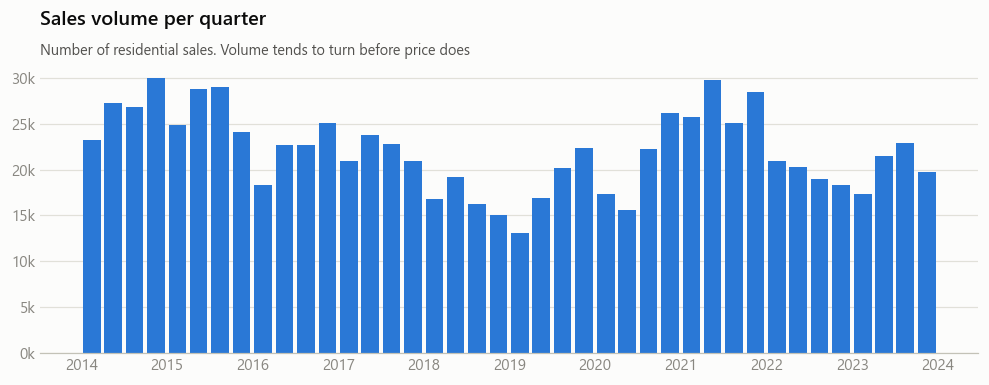

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(x, q.sales, width=75, color=SEGMENT_COLORS["House"])
ax.set_title("Sales volume per quarter")
subtitle(ax, "Number of residential sales. Volume tends to turn before price does")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
fig.savefig(FIG / "q1_volume.png")
plt.show()

### Finding (Q1): Sydney went through two full boom-bust cycles, and inflation explains most of the headline growth

| | Change |
|---|---:|
| Median price 2014 → 2023 (nominal) | **+48.6%** ($690k → $1.025M) |
| Sydney CPI over the same period | +29.1% |
| Median price 2014 → 2023 (**real**) | **+16.9%** |
| 2017 peak → 2019 trough | −11.0% |
| 2019 trough → 2021 peak (COVID boom) | **+35.8%** |
| 2021 peak → 2023 trough (rate hikes) | −10.5% |

- **Most of the headline gain was inflation.** In real terms, the 2023 median sat about 7% below the 2021 peak.
- **The cycles are big.** Each downturn took about 10–11% off prices, and the COVID boom added 36% in roughly two years.
  When a fund buys in the cycle matters far more than *which month* it buys in (see Q5).
- **Volume moved first.** Quarterly sales fell to about 13k in early 2019, the low point of the decade, then climbed
  steadily through 2020–21 before prices surged.

> **What this means for the fund:** watch sales volume as a leading indicator. A sustained rise in volume from a trough
> has come before the last price upswing. Report returns in real terms: a 49% nominal gain sounds strong, but it was
> 17% after inflation.
>
> *Caveat:* the all-dwelling median mixes houses and units, so it understates house growth. Q3 splits them.

## Q3 · Houses vs units: which kept pace with inflation?

**Data note: why townhouses aren't tracked separately over time.** Townhouses were split out in cleaning
(the source labels them "house"). But their count falls sharply over the decade while the total share of strata
sales stays steady. That points to a change in how addresses are recorded, not a market shift: later townhouse
sales have unit-style addresses ("5/12 Smith St"), so they're classified as units. The three-way split is fine for
price *levels*, but for *growth* it would be misleading. Trends below therefore compare **House vs Unit/Townhouse
(all strata)**, two groups that are defined the same way every year.

In [5]:
counts = pd.crosstab(sales.year, sales.dwelling_type)
counts["strata_share_%"] = (counts["Unit"] + counts["Townhouse/Villa"]) / counts.sum(axis=1) * 100
counts

dwelling_type,House,Townhouse/Villa,Unit,strata_share_%
year,,,,
2014,51550,6590,49247,52.0
2015,49438,7797,49664,53.8
2016,42670,5328,40850,52.0
2017,41309,5428,41738,53.3
2018,34162,3411,29678,49.2
2019,38567,2624,31219,46.7
2020,44258,2674,34424,45.6
2021,56740,2807,49536,48.0
2022,40117,1385,36954,48.9


Each segment's median is indexed to **2014 = 100**, so growth rates can be compared on one scale.

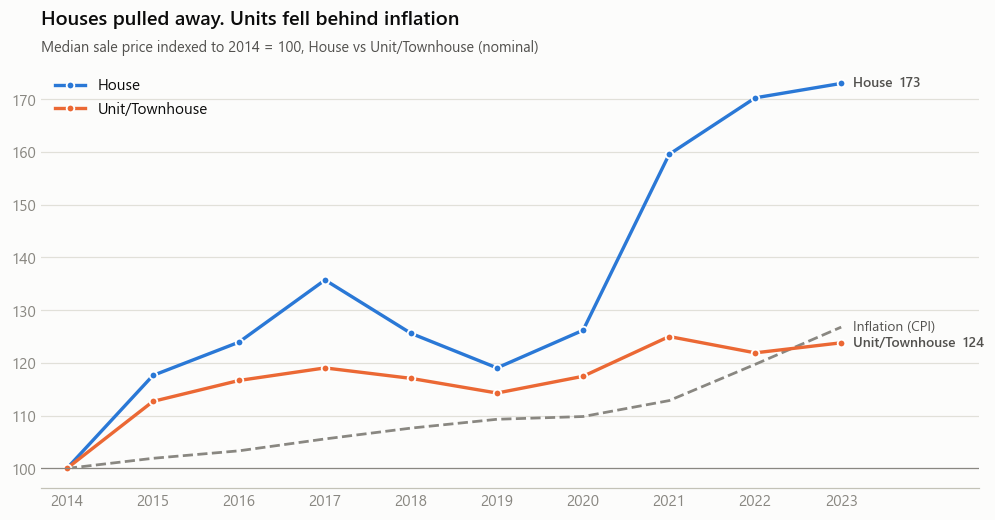

In [6]:
yt = sales.groupby(["year", "segment"]).agg(nominal=("purchase_price", "median"),
                                                  real=("real_price", "median")).unstack()
idx = yt["nominal"] / yt["nominal"].iloc[0] * 100
cpi_year = cpi.groupby(cpi.index.str[:4].astype(int)).mean()
cpi_idx = cpi_year.loc[idx.index] / cpi_year.loc[idx.index[0]] * 100

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(idx.index, cpi_idx, color=MUTED, ls="--", lw=1.8)
ax.annotate("Inflation (CPI)", (idx.index[-1], cpi_idx.iloc[-1]), xytext=(8, 0),
            textcoords="offset points", va="center", color=INK_2, fontsize=9)
for t in SEGMENT_ORDER:
    ax.plot(idx.index, idx[t], color=SEGMENT_COLORS[t], lw=2.2, marker="o", ms=5,
            markeredgecolor="white", markeredgewidth=1.2, label=t)
    ax.annotate(f"{t}  {idx[t].iloc[-1]:.0f}", (idx.index[-1], idx[t].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9, fontweight="semibold")
ax.axhline(100, color=MUTED, lw=0.8)
ax.set_xlim(idx.index[0] - 0.3, idx.index[-1] + 1.6)
ax.set_xticks(idx.index)
ax.set_title("Houses pulled away. Units fell behind inflation")
subtitle(ax, "Median sale price indexed to 2014 = 100, House vs Unit/Townhouse (nominal)")
ax.legend(loc="upper left")
fig.savefig(FIG / "q3_dwelling_index.png")
plt.show()

**How reliable is this?** The medians are from large samples, but a fund should see the uncertainty.
Below: 2014→2023 median growth with a **95% bootstrap confidence interval**. The sales in each year are
resampled 1,000 times, and the spread of the growth estimates shows how much the headline number could move
by chance alone.

In [7]:
rng = np.random.default_rng(42)

def boot_growth(a, b, n=1000):
    a, b = np.asarray(a), np.asarray(b)
    ga = np.median(rng.choice(a, (n, len(a))), axis=1)
    gb = np.median(rng.choice(b, (n, len(b))), axis=1)
    return (gb / ga - 1) * 100

rows = []
for t in SEGMENT_ORDER:
    s = sales[sales.segment == t]
    a_nom, b_nom = s.loc[s.year == 2014, "purchase_price"], s.loc[s.year == 2023, "purchase_price"]
    a_real, b_real = s.loc[s.year == 2014, "real_price"], s.loc[s.year == 2023, "real_price"]
    bn, br = boot_growth(a_nom, b_nom), boot_growth(a_real, b_real)
    rows.append({"segment": t,
                 "median_2014": a_nom.median(), "median_2023": b_nom.median(),
                 "nominal_growth_%": (b_nom.median() / a_nom.median() - 1) * 100,
                 "nominal_CAGR_%": ((b_nom.median() / a_nom.median()) ** (1 / 9) - 1) * 100,
                 "real_growth_%": (b_real.median() / a_real.median() - 1) * 100,
                 "real_95CI_low": np.percentile(br, 2.5), "real_95CI_high": np.percentile(br, 97.5),
                 "sales_2023": len(b_nom)})
growth = pd.DataFrame(rows).set_index("segment")
growth

,median_2014,median_2023,nominal_growth_%,nominal_CAGR_%,real_growth_%,real_95CI_low,real_95CI_high,sales_2023
segment,,,,,,,,
House,"840,000.0","1,453,000.0",73.0,6.3,37.2,35.4,38.2,39569
Unit/Townhouse,"630,000.0","780,000.0",23.8,2.4,-2.2,-3.1,-1.7,41930


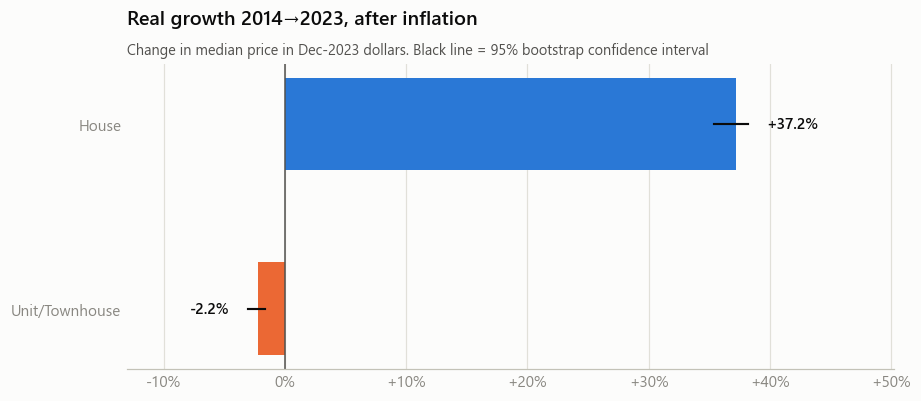

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
yy = np.arange(len(growth))[::-1]
for yi, (t, r) in zip(yy, growth.iterrows()):
    ax.barh(yi, r["real_growth_%"], height=0.5, color=SEGMENT_COLORS[t])
    ax.plot([r.real_95CI_low, r.real_95CI_high], [yi, yi], color="#0b0b0b", lw=1.4)
    off = 1.5 if r["real_growth_%"] >= 0 else -1.5
    ax.text(max(r.real_95CI_high, 0) + 1.5 if r["real_growth_%"] >= 0 else min(r.real_95CI_low, 0) - 1.5,
            yi, f"{r['real_growth_%']:+.1f}%", va="center",
            ha="left" if r["real_growth_%"] >= 0 else "right", fontsize=10, fontweight="semibold")
ax.set_yticks(yy, growth.index)
ax.axvline(0, color=INK_2, lw=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
pct_axis(ax, "x")
lo = min(growth.real_95CI_low.min(), 0) - 10
ax.set_xlim(lo, growth.real_95CI_high.max() + 12)
ax.set_title("Real growth 2014→2023, after inflation")
subtitle(ax, "Change in median price in Dec-2023 dollars. Black line = 95% bootstrap confidence interval")
fig.savefig(FIG / "q3_real_growth.png")
plt.show()

In [9]:
gap = (yt["nominal"]["House"] / yt["nominal"]["Unit/Townhouse"])
print("House median as a multiple of the unit/townhouse median:")
print(gap.round(2).to_string())

House median as a multiple of the unit/townhouse median:
year
2014   1.3
2015   1.4
2016   1.4
2017   1.5
2018   1.4
2019   1.4
2020   1.4
2021   1.7
2022   1.9
2023   1.9


### Finding (Q3): Houses returned 37% after inflation. Units and townhouses lost value in real terms

| Segment | 2014 median | 2023 median | Nominal growth (p.a.) | **Real growth** (95% CI) |
|---|---:|---:|---:|---:|
| House | $840k | $1.453M | +73.0% (6.3% p.a.) | **+37.2%** (35.4% to 38.2%) |
| Unit/Townhouse | $630k | $780k | +23.8% (2.4% p.a.) | **−2.2%** (−3.1% to −1.7%) |

- **The gap is statistically clear.** The confidence intervals are narrow and far apart, so this isn't noise from sampling.
- **Almost all of the divergence happened in the COVID boom.** A house cost 1.3–1.5× a unit from 2014 to 2020. That
  jumped to **1.9× in 2021–23**, as buyers chased space during lockdowns and working from home.
- Units' nominal growth (2.4% a year) was **below inflation**, so a 2014 unit buyer lost purchasing power on capital value.

> **What this means for the fund:** on capital growth alone, houses clearly outperformed. Two things to weigh before
> concluding "houses only":
> 1. **Yield isn't measured here.** Units usually earn a higher rental yield, which offsets part of the growth gap.
>    Total return needs rent data, which is a recommended next data source.
> 2. **The house-to-unit price multiple is at a decade high (1.9×).** If it reverts even part-way toward the 1.4×
>    average, units would outperform. Treat that as a hypothesis to monitor, not a forecast.

## Q5 · Is there a best time of year to buy?

Raw monthly medians suggest January is dramatically cheaper. Before telling the fund to buy in January,
we need to check whether **January homes are cheaper, or just different homes are selling**.
The January effect is broken down in three steps:

1. **Raw:** each month's median vs the year's median.
2. **Suburb-adjusted:** each sale compared with its own suburb and dwelling type, which removes *where* sales happen.
3. **Seasonal decomposition:** the suburb-adjusted monthly series split into trend and seasonal parts
   (`statsmodels.seasonal_decompose`), which also removes normal price growth *within* the year.

In [10]:
sales["log_p"] = np.log(sales.purchase_price)
houses = sales[sales.segment == "House"]

# 1. Raw: month median vs that year's median
m = houses.groupby(["year", "month"]).purchase_price.median()
raw = (m / m.groupby(level=0).transform("median") - 1).groupby(level=1).mean() * 100

# 2. Suburb-adjusted: log price vs its suburb-year median
rel = houses.log_p - houses.groupby(["suburb", "year"]).log_p.transform("median")
suburb_adj = np.expm1(rel.groupby(houses.month).mean()) * 100

# 3. Seasonal component of the suburb-adjusted monthly series (removes within-year trend)
def seasonal_effect(df):
    adj = df.log_p - df.groupby("suburb").log_p.transform("mean")
    s = adj.groupby(df.contract_date.dt.to_period("M").dt.to_timestamp()).mean()
    dec = seasonal_decompose(s, model="additive", period=12)
    return np.expm1(dec.seasonal.groupby(dec.seasonal.index.month).first()) * 100

seasonal = {t: seasonal_effect(sales[sales.segment == t]) for t in SEGMENT_ORDER}

onion = pd.DataFrame({"1. Raw median": raw, "2. Suburb-adjusted": suburb_adj,
                      "3. True seasonal effect": seasonal["House"]})
onion.index.name = "month"
top_q_share = (houses.purchase_price >= houses.groupby("year").purchase_price.transform(lambda s: s.quantile(.75)))
print("Share of house sales in the year's top price quartile: January "
      f"{top_q_share[houses.month == 1].mean():.0%} vs other months {top_q_share[houses.month != 1].mean():.0%}")
onion.round(1)

Share of house sales in the year's top price quartile: January 14% vs other months 26%


,1. Raw median,2. Suburb-adjusted,3. True seasonal effect
month,,,
1,-21.1,-7.2,-3.3
2,-3.1,-3.4,-0.4
3,2.8,-1.4,1.1
4,0.5,-0.9,0.7
5,-0.1,-0.3,0.8
6,-0.1,-0.3,0.1
7,-5.8,0.1,-0.3
8,-0.4,1.4,0.1
9,4.7,3.1,1.2


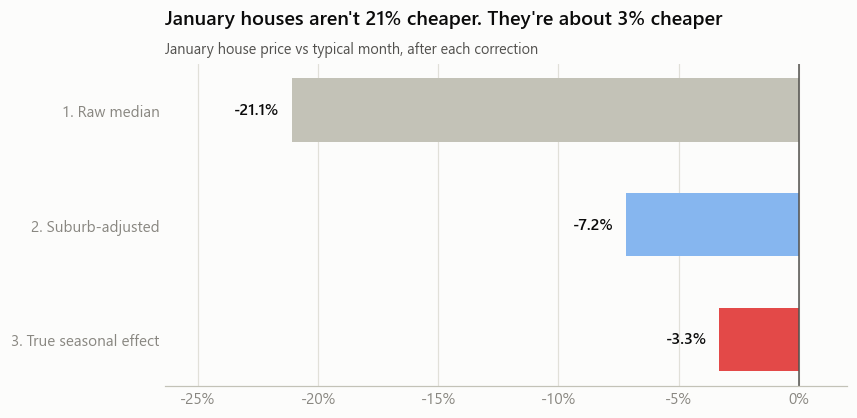

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = onion.columns
vals = onion.loc[1].values
colors = ["#c3c2b7", "#86b6ef", NEG]
ax.barh(np.arange(3)[::-1], vals, height=0.55, color=colors)
for yi, v in zip(np.arange(3)[::-1], vals):
    ax.text(v - 0.5, yi, f"{v:+.1f}%", ha="right", va="center", fontsize=10.5, fontweight="semibold")
ax.set_yticks(np.arange(3)[::-1], labels)
ax.axvline(0, color=INK_2, lw=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
pct_axis(ax, "x")
ax.set_xlim(vals.min() * 1.25, 2)
ax.set_title("January houses aren't 21% cheaper. They're about 3% cheaper")
subtitle(ax, "January house price vs typical month, after each correction")
fig.savefig(FIG / "q5_january_breakdown.png")
plt.show()

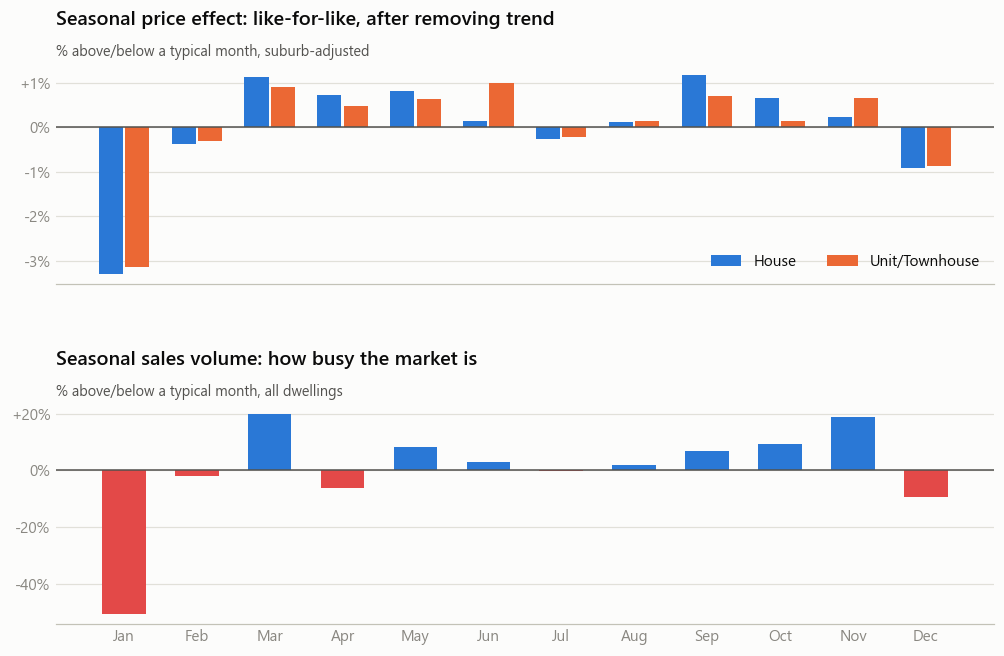

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
price_House,-3.3,-0.4,1.1,0.7,0.8,0.1,-0.3,0.1,1.2,0.6,0.2,-0.9
price_Unit/Townhouse,-3.1,-0.3,0.9,0.5,0.6,1.0,-0.2,0.1,0.7,0.1,0.7,-0.9
volume_all,-50.6,-1.9,19.8,-6.1,8.4,3.0,-0.3,1.9,7.0,9.4,18.8,-9.2


In [12]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
vol = sales.groupby(sales.contract_date.dt.to_period("M").dt.to_timestamp()).size()
dv = seasonal_decompose(vol, model="multiplicative", period=12)
vol_eff = (dv.seasonal.groupby(dv.seasonal.index.month).first() - 1) * 100

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={"hspace": 0.55})
w = 0.36
for i, t in enumerate(SEGMENT_ORDER):
    a1.bar(np.arange(12) + (i - 0.5) * w, seasonal[t].values, width=w - 0.03, color=SEGMENT_COLORS[t], label=t)
a1.axhline(0, color=INK_2, lw=1)
pct_axis(a1, decimals=0)
a1.set_title("Seasonal price effect: like-for-like, after removing trend")
subtitle(a1, "% above/below a typical month, suburb-adjusted")
a1.legend(ncol=2, loc="lower right")

a2.bar(np.arange(12), vol_eff.values, width=0.6, color=[NEG if v < 0 else POS for v in vol_eff.values])
a2.axhline(0, color=INK_2, lw=1)
pct_axis(a2)
a2.set_title("Seasonal sales volume: how busy the market is")
subtitle(a2, "% above/below a typical month, all dwellings")
a2.set_xticks(range(12), MONTHS)
fig.savefig(FIG / "q5_seasonality.png")
plt.show()
pd.DataFrame({**{f"price_{t}": seasonal[t].values for t in SEGMENT_ORDER}, "volume_all": vol_eff.values},
             index=MONTHS).round(1).T

### Finding (Q5): January is about 3% cheaper like-for-like, and the raw data overstates it seven-fold

| January vs a typical month (houses) | Effect |
|---|---:|
| Raw median | −21.1% |
| After controlling for suburb | −7.2% |
| After also removing the within-year trend (**true seasonal effect**) | **−3.3%** |

- **Most of the raw January dip is about which homes sell.** Only 14% of January house sales are in the year's
  top price quartile, against 26% in other months. Prestige sellers wait until after the holidays.
- **The real discount is about 3%** for houses and units alike. On a $1.45M house, that's about **$48k**.
- **The catch is that there's half the choice.** January sales volume is **51% below** a typical month. March (+20%)
  and November (+19%) are the busiest months, and March and September are slightly above typical on price (about +1%).

> **What this means for the fund:** build the acquisition pipeline in Nov–Dec and aim to **exchange in December or
> January**, when competition and prices are lowest. But keep this in proportion: a 3% seasonal edge is small next to
> the 10–36% cycle swings in Q1. Cycle timing matters more than calendar timing.
>
> *Method note:* this is a good example of why a raw median can mislead. A naive analysis would have reported a
> 21% January discount, roughly seven times the real effect.

In [13]:
# Export for the dashboard app
EXPORT = ROOT / "data" / "exports"
EXPORT.mkdir(parents=True, exist_ok=True)
seasonality = pd.DataFrame({"month": MONTHS, **{t: seasonal[t].values for t in SEGMENT_ORDER},
                            "volume_all": vol_eff.values})
seasonality = seasonality.melt(id_vars=["month", "volume_all"], var_name="segment", value_name="price_effect_%")
seasonality = seasonality.rename(columns={"volume_all": "volume_effect_%"})
seasonality["month_num"] = seasonality.month.map({m: i + 1 for i, m in enumerate(MONTHS)})
seasonality.round(3).to_csv(EXPORT / "seasonality.csv", index=False)

cycle_tbl = y.reset_index().round(1)
cycle_tbl.to_csv(EXPORT / "annual_market.csv", index=False)
print("exported seasonality.csv, annual_market.csv")

exported seasonality.csv, annual_market.csv


## Summary for the fund

1. **Real returns were modest overall.** The Sydney median rose 49% from 2014 to 2023, but only **17% after inflation**.
2. **Houses clearly beat units:** **+37% real** for houses vs **−2% real** for units and townhouses. The gap opened almost
   entirely in the 2021–22 COVID boom.
3. **The house-to-unit price multiple is at a decade high (1.9×).** That's a potential opportunity in units if it
   narrows, but it needs rental yield data to assess properly.
4. **Timing the cycle matters about 10× more than timing the month.** Cycles moved prices 10–36%, and seasonality only ~3%.
5. **For purchase timing,** prices are about 3% lower like-for-like in January, with half the stock to choose from. Sales
   volume is a useful leading indicator of the cycle.

**Next (Notebook 02):** which suburbs grew fastest (Q2), and how volatile each one is (Q7). This uses a repeat-sales
index, which compares the same property sold twice and removes the "what sold" bias flagged throughout this notebook.